In [16]:
import pandas as pd
statdata = pd.read_csv('./data/statdata.csv')
statdata

,description,ranking_method,replica_no,name,cpu_time,feature_rank,recall,precision,fpr,f1,roc_fpr,roc_tpr
0,"Continuous Features [p=20,n=1600,p_=2,h=0.4,ed...",RFE w/XGBoost,1,Continuous Features,3.855204,4.0,1.0,0.333333,0.222222,0.500000,0.222222,1.000000
1,"Continuous Features [p=20,n=1600,p_=2,h=0.4,ed...",RFE w/XGBoost,1,Continuous Features,3.855204,11.0,1.0,0.100000,1.000000,0.181818,1.000000,1.000000
2,"Continuous Features [p=20,n=1600,p_=2,h=0.4,ed...",RFE w/XGBoost,1,Continuous Features,3.855204,5.0,1.0,0.250000,0.333333,0.400000,0.333333,1.000000
3,"Continuous Features [p=20,n=1600,p_=2,h=0.4,ed...",RFE w/XGBoost,1,Continuous Features,3.855204,3.0,1.0,0.500000,0.111111,0.666667,0.111111,1.000000
4,"Continuous Features [p=20,n=1600,p_=2,h=0.4,ed...",RFE w/XGBoost,1,Continuous Features,3.855204,11.0,1.0,0.100000,1.000000,0.181818,1.000000,1.000000
...,...,...,...,...,...,...,...,...,...,...,...,...
168507,"2 Additive Main Effects [p=20,n=1600,p_=2,h=0....",MultiSURF,24,2 Additive Main Effects,24.113497,2.0,1.0,1.000000,0.000000,1.000000,0.000000,1.000000
168508,"2 Additive Main Effects [p=20,n=1600,p_=2,h=0....",MultiSURF,24,2 Additive Main Effects,24.113497,1.0,0.5,1.000000,0.000000,0.666667,0.000000,0.500000
168509,"2 Additive Main Effects [p=20,n=1600,p_=2,h=0....",FeatBoost,24,2 Additive Main Effects,24.860639,1.0,0.0,0.000000,0.050000,NaN,0.050505,0.000532
168510,"2 Additive Main Effects [p=20,n=1600,p_=2,h=0....",FeatBoost,24,2 Additive Main Effects,24.860639,2.0,0.5,0.500000,0.052632,0.500000,0.050505,0.479798


In [17]:
subset = statdata.copy()
subset = subset[subset['name'] != 'Missing Values']
subset = subset[subset['name'] != 'Continuous Endpoints (Threshold)']
subset = subset[subset['name'] != 'Continuous Endpoints (GAMETES)']
subset = subset[subset['ranking_method'] != 'Stability Selection']
# subset = subset[subset['description'].str.contains('h=1')]
print(statdata.shape)
print(subset.shape)

(168512, 12)
(163122, 12)


F1 scores

Text(0.5, 1.0, 'f1 scores per unique dataset')

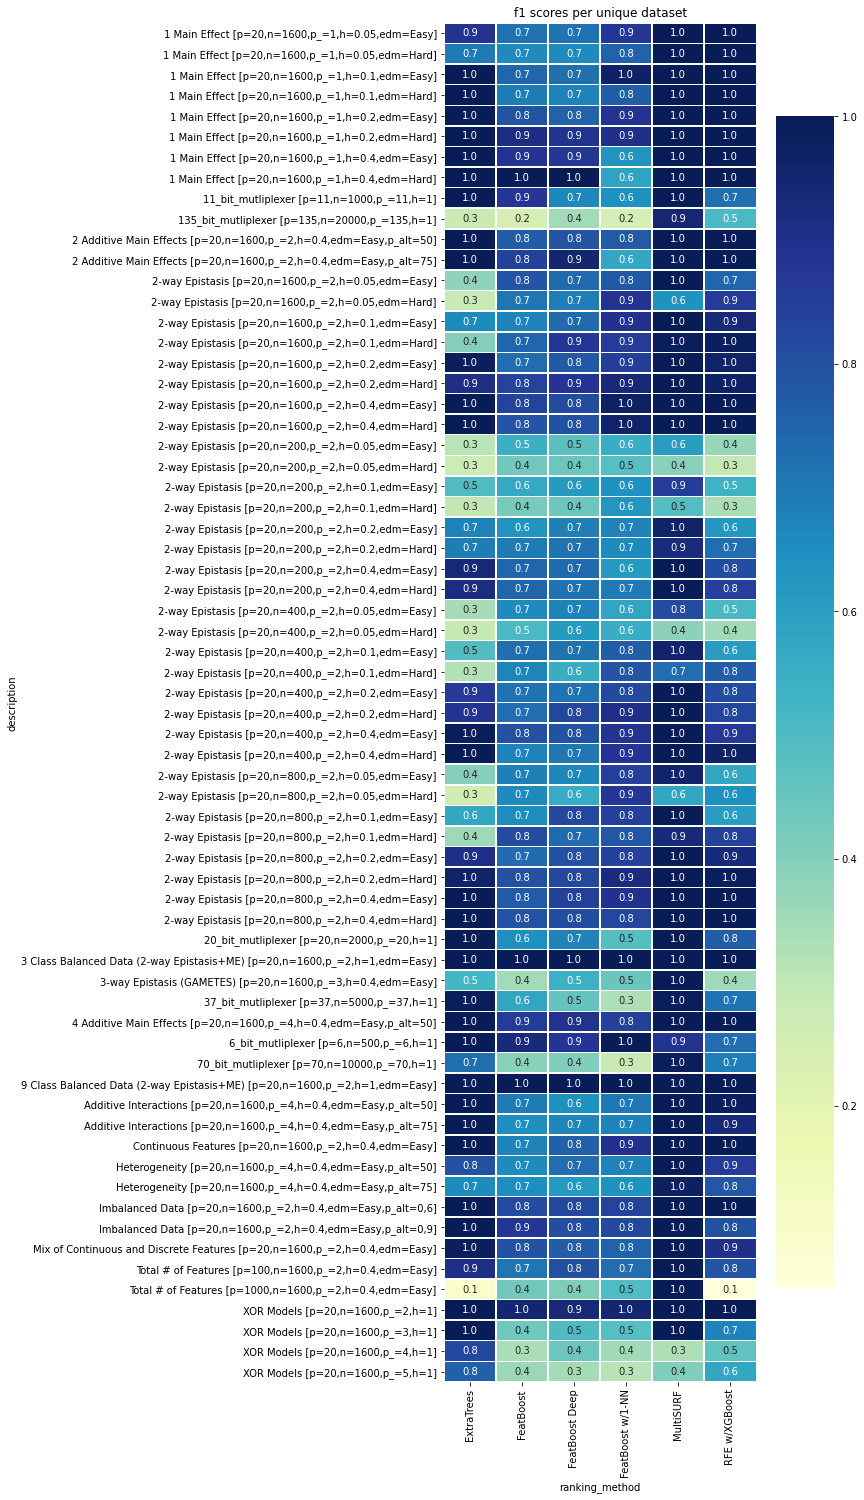

In [4]:
max_f1 = subset.groupby(['description', 'ranking_method', 'replica_no']).agg({'f1': 'max'})
mean_f1 = max_f1.reset_index().groupby(['description', 'ranking_method']).agg({'f1': 'mean'})
maxmean = mean_f1.reset_index()

import seaborn as sns
import matplotlib.pyplot as plt
rectangular = pd.pivot_table(maxmean,\
    values='f1',\
    index=['description'],\
    columns=['ranking_method'])
f, ax = plt.subplots(figsize=(7, 25))
plt.yticks(rotation=0)
plt.xticks(rotation=0)
ax = sns.heatmap(rectangular, annot=True, fmt=".1f", linewidths=.5, cmap="YlGnBu", yticklabels=True, ax=ax)
plt.title('f1 scores per unique dataset')

PR and ROC Curve

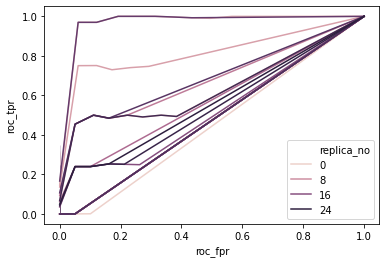

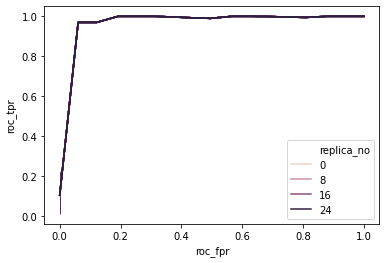

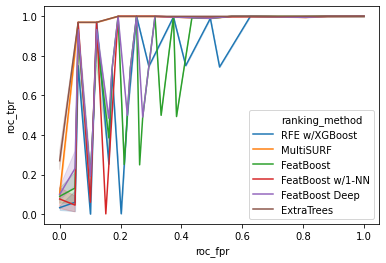

In [44]:
small_subset = subset[subset['description'].str.contains('h=1')]
zero_points = small_subset.copy()
zero_points['roc_fpr'] = 0
zero_points['roc_tpr'] = 0
one_points = small_subset.copy()
one_points['roc_fpr'] = 1
one_points['roc_tpr'] = 1
entire_subset = pd.concat([small_subset, zero_points, one_points])
# pr curve
# g = sns.relplot(x='recall', y='precision', hue='ranking_method', style='ranking_method',
#                 col='description', kind='line', err_style=None,
#                 data=small_subset, col_wrap=3, facet_kws={'sharex': False, 'sharey': False})
# roc curve
# g = sns.relplot(x='roc_fpr', y='roc_tpr', hue='ranking_method', style='ranking_method',
#                 col='description', kind='line',
#                 data=entire_subset, col_wrap=3, facet_kws={'sharex': False, 'sharey': False})
# print(small_subset['name'])
supersmally = entire_subset[entire_subset['name'] == '20_bit_mutliplexer']
supersmall = supersmally[supersmally['ranking_method'] == 'FeatBoost']
sns.lineplot(data=supersmall, x='roc_fpr', y='roc_tpr', hue='replica_no')
plt.show()
supersmall2 = supersmally[supersmally['ranking_method'] == 'MultiSURF']
sns.lineplot(data=supersmall2, x='roc_fpr', y='roc_tpr', hue='replica_no')
plt.show()
sns.lineplot(data=supersmally, x='roc_fpr', y='roc_tpr', hue='ranking_method')
plt.show()

Text(0.5, 1.0, 'recall per ranking method for all datasets')

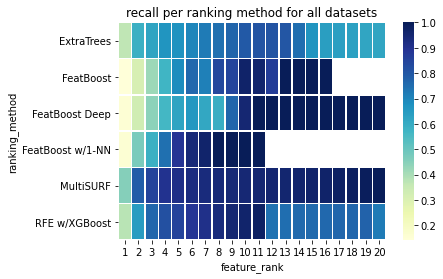

In [7]:
subset2 = subset[subset['feature_rank'] <= 20]

from matplotlib.ticker import FuncFormatter
rectangular = pd.pivot_table(subset2,\
    values='recall',\
    index=['ranking_method'],\
    columns=['feature_rank'])
g = sns.heatmap(rectangular,\
    linewidths=.5, cmap="YlGnBu")
plt.yticks(rotation=0)
plt.xticks(rotation=0)
plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, _: int(x) + 1))
plt.title('recall per ranking method for all datasets')

Construct a sensible subset for plotting

In [55]:
# subset = statdata.copy()
# for dataset, data in statdata.groupby('description'):
#     all_replicas = data.groupby('replica_no')
#     if len(all_replicas.count()) != 24: # only 'finished' datasets
#         subset = subset[subset['description'] != dataset]
#     else: # add newline in plot title
#         descr = dataset.replace(' [p=', '\n[p=')
#         descr = descr.replace(',h=', ',\nh=')
#         subset = subset.replace({ 'description': dataset }, descr)
#         # short_descr = '[p=' + dataset.split(' [p=')[1]
#         # entries = subset[subset['description'] == dataset]
#         # subset.loc[entries.index, 'short_descr'] = short_descr
# subset = subset[subset['feature_rank'] <= 20]
# subset = subset[subset['ranking_method'] != 'Stability Selection']
# subset.shape

(89214, 20)

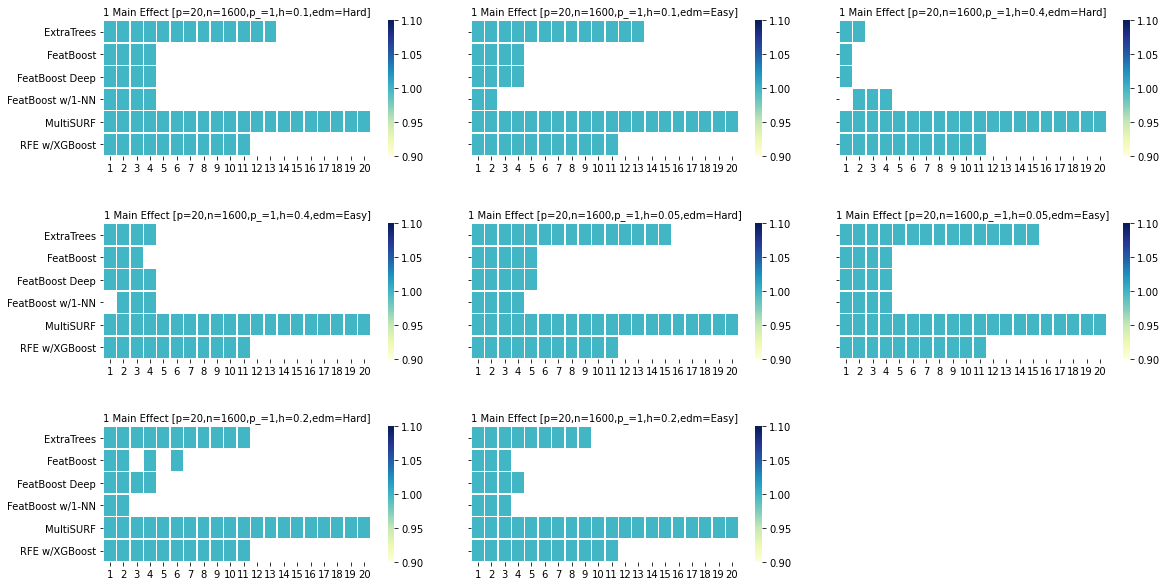

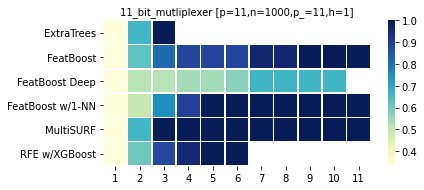

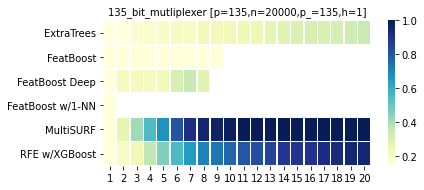

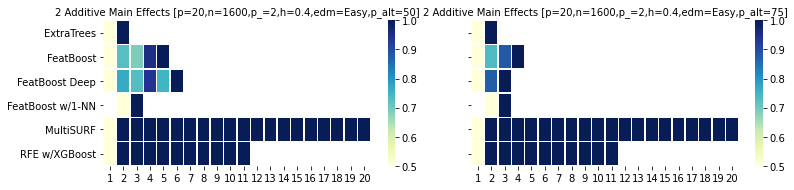

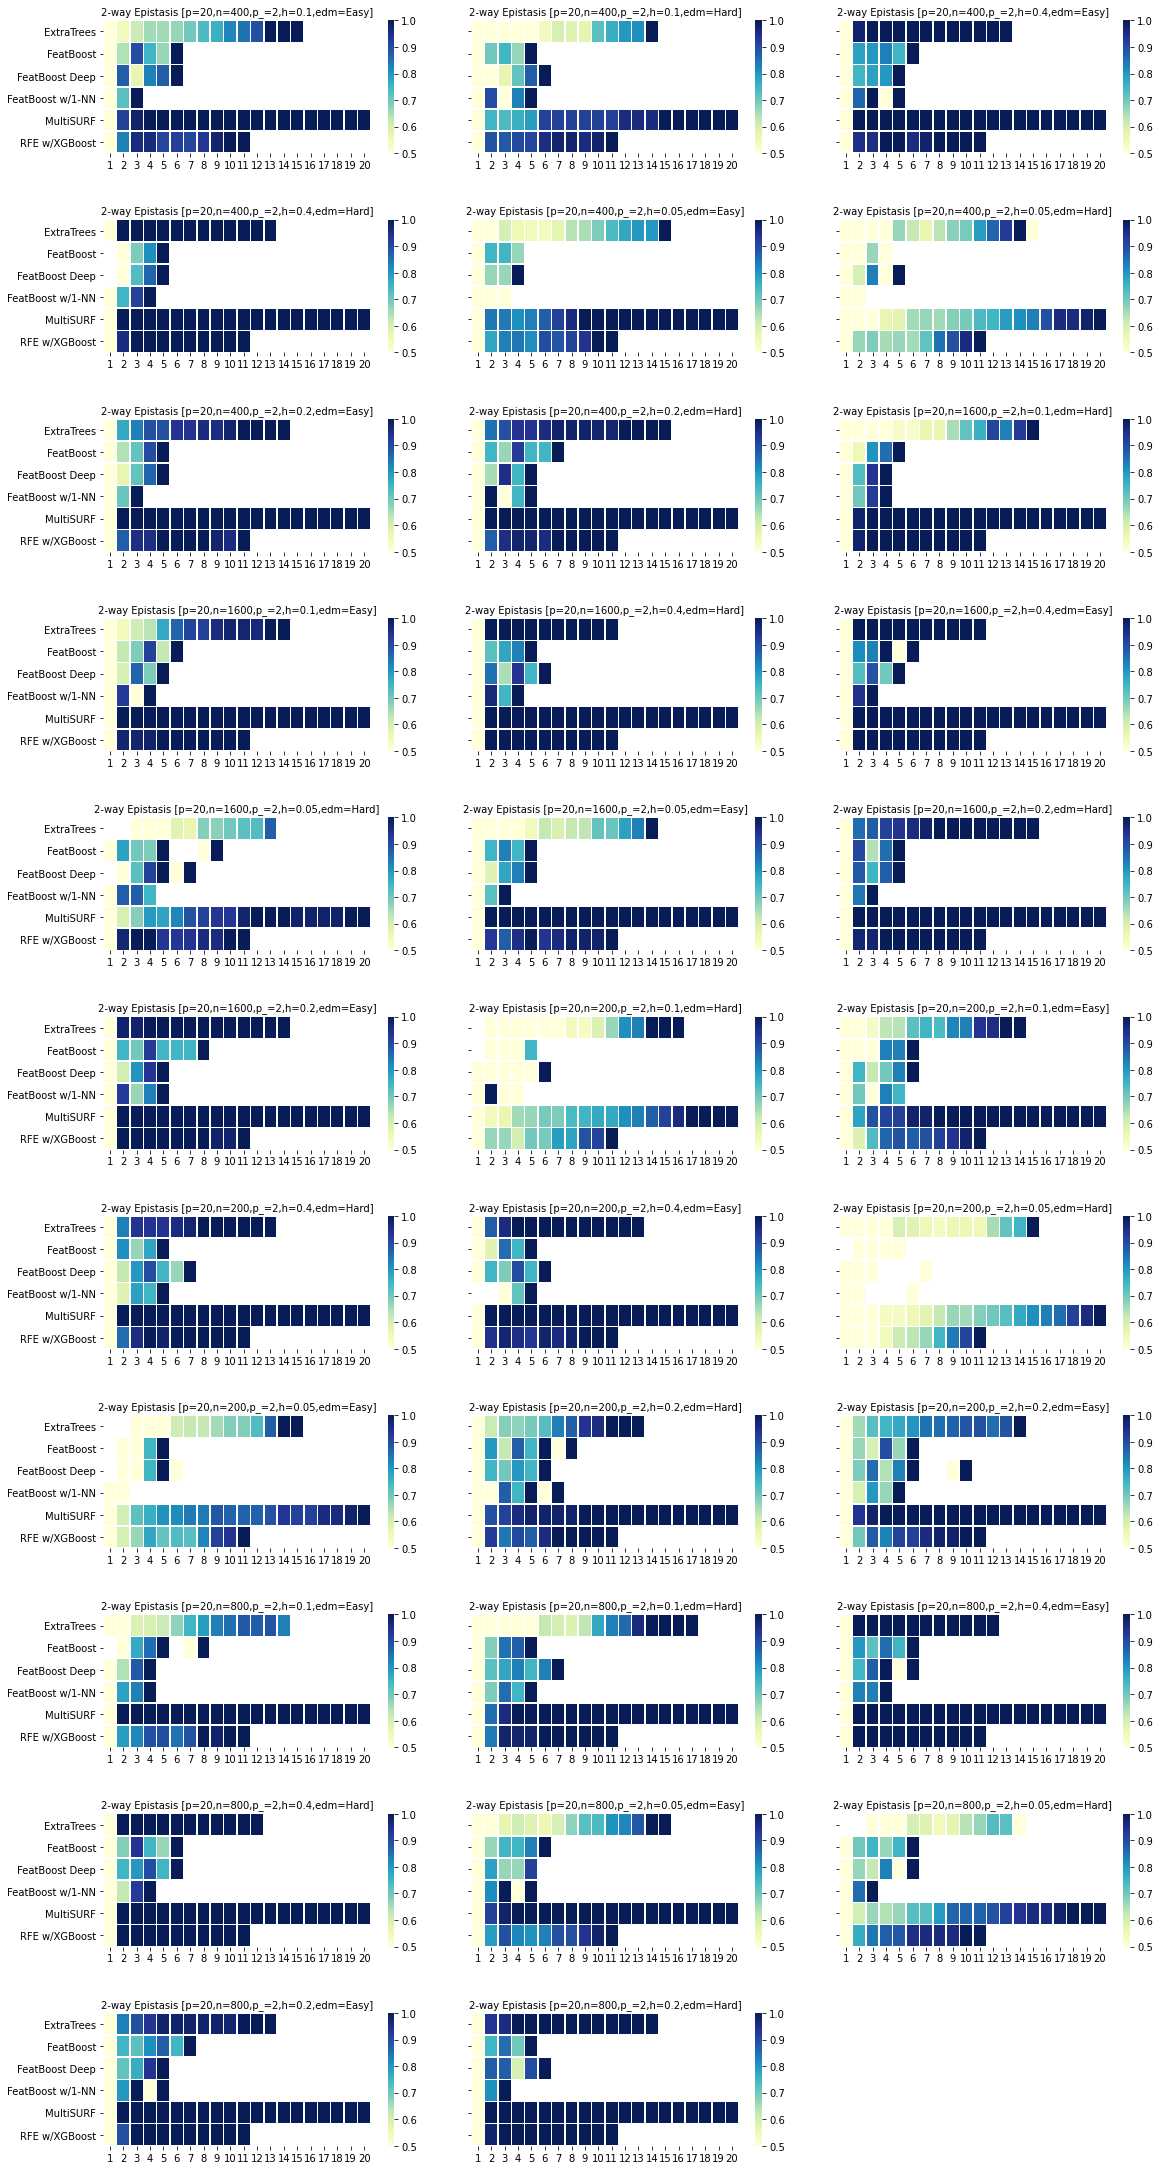

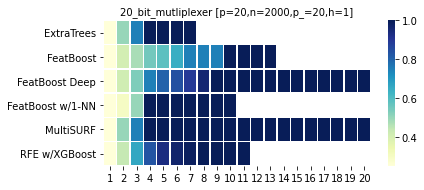

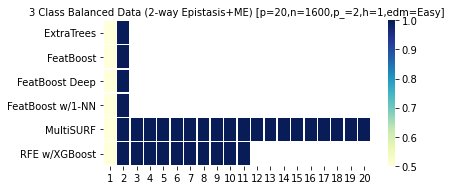

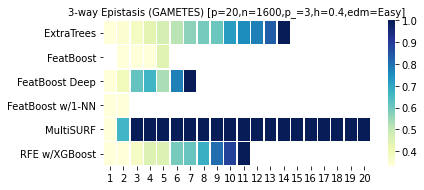

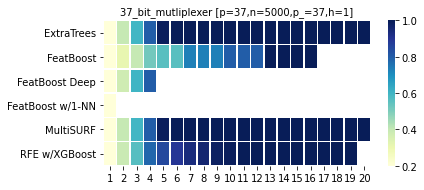

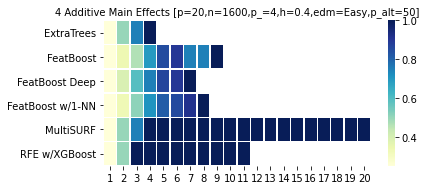

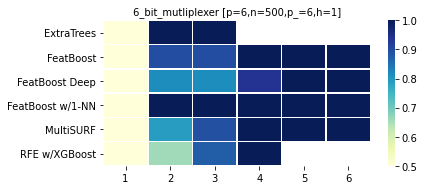

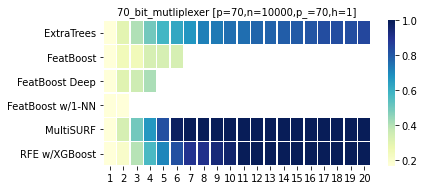

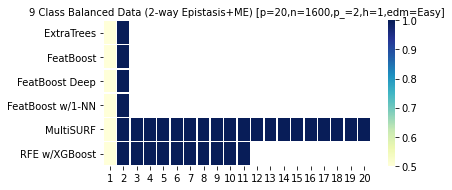

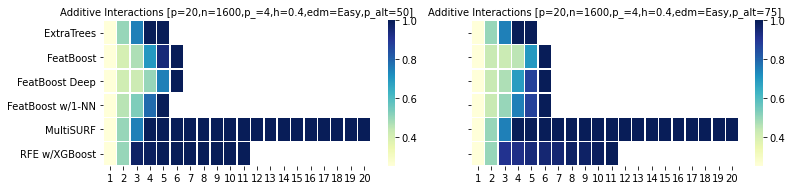

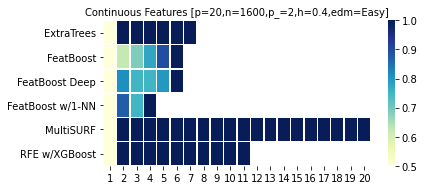

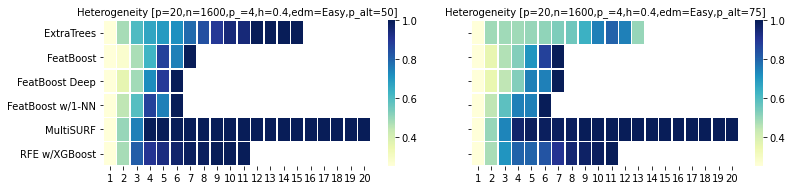

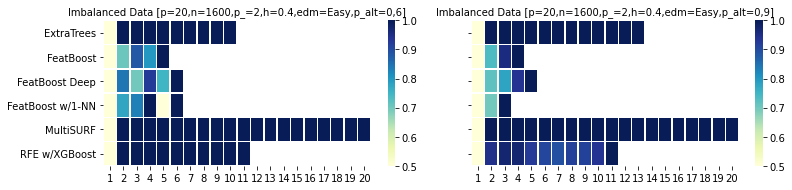

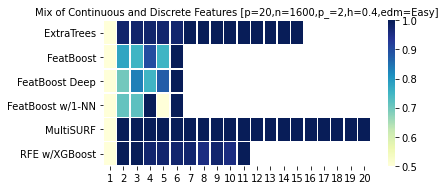

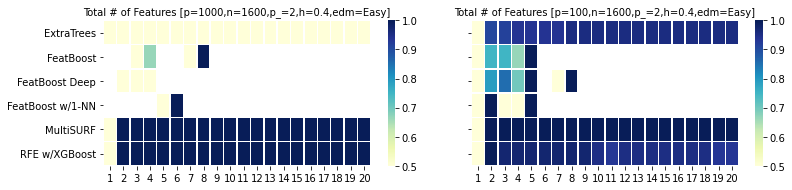

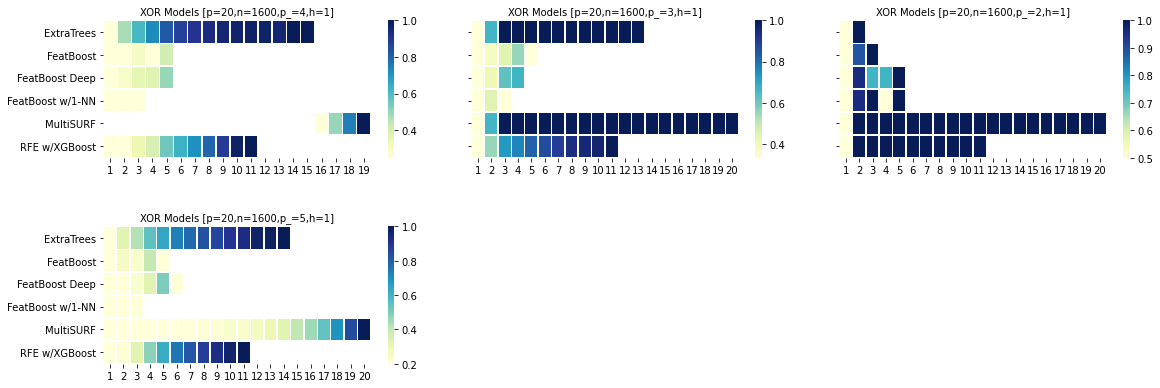

In [8]:
def draw_heatmap(*args, **kwargs):
    data = kwargs.pop('data')
    rect = pd.pivot_table(data, values='recall',\
                        index=['ranking_method'],\
                        columns=['feature_rank'])
    sns.heatmap(rect, linewidths=.5, cmap="YlGnBu")
    plt.gca().xaxis.set_major_formatter(FuncFormatter(lambda x, _: int(x) + 1))
    plt.yticks(rotation=0)
    plt.xticks(rotation=0)

def pltrecall(data, title):
    fg = sns.FacetGrid(data, col='description', sharex=False, col_wrap=3, size=2.75, aspect=2)
    fg.map_dataframe(draw_heatmap).set_titles("{col_name}")
    fg.fig.subplots_adjust(wspace=0.1, hspace=0.5)
    # plt.subplots_adjust(top=0.875)
    # fg.fig.suptitle(title)
    # fg.fig.tight_layout()

for name, data in subset2.groupby('name'):
    pltrecall(data, name)